# Process A – visual analysis (README)

**What this notebook is:** plots to *see* process A (161 labelled batches, 161 test batches, 11 sensor variables, no missing values). Colours are the same in every plot: **grey = accepted, orange = rejected, blue = test (unlabelled)**. Individually highlighted batches get their own colour *and* line style. Sections below follow the plots; the key findings are here.

## Key findings

1. **25 % of batches are rejected (40 / 161).** Batches come in two typical lengths, ~2380 and ~2720 timesteps, in both classes; a handful are much shorter (`A_232` 196 – rejected, `A_149` 1166 – accepted, `A_215` 1720 – rejected, `A_285` 1794 – accepted). Length alone says little (AUC ≈ 0.63). (§1)
2. **Within a batch the process is flat.** Apart from a ramp at the start and end of `density`, variables are stationary noise around a batch-specific level. The information is therefore in *per-batch levels and noise*, not in a time pattern. (§2)
3. **A group of rejected batches are level outliers**, often with the *same* offsets repeating (sensor/calibration-like states): `temperature_4` ≈ −15.3 (`A_051`, `A_256`, `A_263`, `A_274`) or ≈ −9.3 (`A_048`, `A_215`, `A_226`); `flow_rate_1` ≈ 121 (4 batches) or ≈ 137 (2); `temperature_3` ≈ 21.7 (3) or > 28 (4). Taking the median per batch and flagging any variable whose distance from the accepted centre exceeds the largest distance among accepted batches (the baseline rule) catches **22 of 40** rejected batches, with **8 / 121** false alarms under leave-one-out. (§3, §5)
4. **The other 18 rejected batches look normal in level – the signal is `temperature_1` noise.** Rejected batches have higher (median 14.3 vs 13.9) and, above all, *noisier* `temperature_1`. Its within-batch std is the best single feature (AUC 0.72): **9 rejected batches have std > 0.25, while the highest accepted batch has 0.24**. These 9 are exactly 9 of the 18 batches the level rule misses (`A_017, A_065, A_104, A_169, A_176, A_189, A_197, A_244, A_298`). Level rule OR `temperature_1_std > 0.25` → **31 of 40** rejected. ⚠ The 0.25 cut was chosen by looking at these plots, so it is optimistic: validate it before trusting it. (§4, §9)
5. **`pressure_2` and `pressure_4` do not separate the classes at all** (no rejected batch flagged by either), and 9 rejected batches (~1/4) remain unexplained by any variable we looked at. (§5)
6. **No drift over the campaign.** Rejected batches are spread across batch numbers 1–320 (rolling rejection rate wanders around 25 %, no trend) and the test batches are interleaved with the calibration ones. (§6)
7. **Batches 101–104:** `A_101`, `A_103` accepted, `A_104` rejected, `A_102` is a *test* batch. `A_104` stands out in `temperature_1`: it climbs steadily from ≈ 13.6 to ≈ 14.5 with a step near 80 % of the batch (and has high `temperature_1` noise, std > 0.25), plus a higher `density`/`pressure_1` level. `A_101` and `A_102` have a high but stable `temperature_1` (~14.7–14.8); `A_103` is typical. (§7)
8. **In 2D (PCA) the classes overlap heavily**; rejected batches are mostly the far-away points on the edges. A linear picture will not separate them – a model needs the specific features above. (§8)
9. **Test looks like calibration.** Batch-level distributions agree, and the test set contains the same outlier states (e.g. `temperature_4` ≈ −15.3, `flow_rate_1` ≈ 121), so the level rule transfers. (§11)

## Caveats
- Everything here is exploratory and in-sample; no model was fitted.
- Batch-level summaries use the median/std over the whole run; they would be affected by the short batches.
- Time axis is *normalised* (0–1) because batch lengths differ.

*Data is read through a parquet cache in `/home/renku/work/parquet_cache/` (outside the repo).*

---
## 0. Setup & data
Loads the data, defines the colour palette and the per-batch summaries (median and standard deviation of every variable) used throughout.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter
from sklearn.decomposition import PCA
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import roc_auc_score
%matplotlib inline
plt.rcParams.update({"figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.25,
                     "axes.titleweight":"bold","axes.titlesize":10,"axes.labelsize":9,"legend.frameon":False,"legend.fontsize":9,
                     "axes.formatter.useoffset":False,"axes.formatter.limits":(-7,7)})   # plain numbers on the axes, no "1e-6 + 4.99996" offsets

# Colour-blind-safe palette (checked for protan/deutan/tritan separation): grey = accepted, orange = rejected, blue = test
ACC,REJ,TEST,INK="#8a8f98","#eb6834","#2a78d6","#333333"
PAL={"accepted":ACC,"rejected":REJ}
# for highlighting individual batches: colour AND line style / marker differ, so identity never relies on colour alone
HL_COL=["#000000","#d55181","#008300","#6250d6","#a6761d"]; HL_LS=["-","--","-.",":",(0,(5,1,1,1))]; HL_MK=["o","s","^","D","v"]
WIN_COL="#f0e442"   # yellow shading for time windows
REJ_MED="#6250d6"   # violet: rejected median, clearly different from the orange single batches
MED_KW=dict(color="#555555",ls="--")   # accepted median when individual batches are drawn on top

# legend helpers
def dot(c,l,m="o",**k): return Line2D([],[],marker=m,ls="",color=c,label=l,markersize=7,**k)
def hollow(c,l): return Line2D([],[],marker="o",ls="",markerfacecolor="none",markeredgecolor=c,label=l,markersize=7)
def line(c=None,l=None,lw=2,label=None,**k): return Line2D([],[],color=k.pop("color",c),label=label or l,lw=lw,**k)
def patch(c,l,a=.4): return Patch(color=c,alpha=a,label=l)
CLASS_LEG=[dot(ACC,"accepted"),dot(REJ,"rejected")]
def top_legend(fig,h,y=1.0,ncol=None,**k): fig.legend(handles=h,loc="lower center",bbox_to_anchor=(.5,y),ncol=ncol or len(h),frameon=False,fontsize=10,**k)
def legend_axis(ax,h,**k): ax.axis("off"); ax.legend(handles=h,loc="center",fontsize=11,**k)
OFF_LEG=Line2D([],[],marker="^",ls="",color="#9a9a9a",markeredgecolor="k",markersize=8,label="▲ ▼ ◀ ▶ = batch beyond the axis, drawn at the edge")

# ---- readable axes: zoom to the bulk of the batches, show extreme batches as triangles at the edge
PLAIN=FuncFormatter(lambda v,_: f"{v:.6g}")
def plain_log(ax,axis="y"):
    """log axis with plain tick labels (0.01, 0.02, 0.05 ... instead of 2×10⁻²)"""
    A=ax.yaxis if axis=="y" else ax.xaxis
    A.set_major_locator(LogLocator(base=10,subs=(1,2,5))); A.set_major_formatter(PLAIN); A.set_minor_formatter(NullFormatter())
def bulk_lims(v,log=False,k=1.5,force=False):
    """axis limits covering the bulk of the values -> (lo, hi, zoomed?). Zooms only when a few extreme values would squash the rest."""
    v=np.asarray(v,float); v=v[np.isfinite(v)]
    if log: v=v[v>0]
    t=np.log10(v) if log else v
    p5,p95=np.percentile(t,[5,95]); full=np.ptp(t) or 1; sp=(p95-p5) or full
    if full<=4*sp and not force: lo,hi,zoom=t.min(),t.max(),False
    else: lo,hi,zoom=max(t.min(),p5-k*sp),min(t.max(),p95+k*sp),True
    pad=.06*((hi-lo) or 1); lo,hi=lo-pad,hi+pad
    return (10**lo,10**hi,zoom) if log else (lo,hi,zoom)
def scatter_clip(ax,x,y,xl,yl,color,s=30,marker="o",hollow_=False,alpha=1,zorder=3):
    """scatter inside the limits; points outside are drawn as triangles at the edge pointing to where they are. Returns (x, y, any clipped)"""
    x=np.asarray(x,float); y=np.asarray(y,float); cx=np.clip(x,*xl); cy=np.clip(y,*yl); inn=(x==cx)&(y==cy)
    kw=dict(facecolors="none",edgecolors=color) if hollow_ else dict(color=color)
    ax.scatter(x[inn],y[inn],s=s,marker=marker,alpha=alpha,zorder=zorder,**kw)
    mk=np.where(y>yl[1],"^",np.where(y<yl[0],"v",np.where(x>xl[1],">","<")))
    for m_ in "^v<>":
        sel=(~inn)&(mk==m_)
        if sel.any(): ax.scatter(cx[sel],cy[sel],marker=m_,color=color,edgecolors="k",linewidths=.6,s=max(s*1.8,45),zorder=zorder+2,clip_on=False)
    return cx,cy,bool((~inn).any())
def class_box(ax,values,classes,ylabel,log="auto",zoom=True):
    """box + one dot per batch, accepted vs rejected. log='auto' uses a log axis when values span > 50x.
    With zoom, the axis covers the bulk of the batches and extreme batches are drawn as triangles at the edge
    (with their number and most extreme value). Returns True if any batch was drawn at the edge."""
    v=np.asarray(values,float); c=np.asarray(classes)
    if log=="auto": log=bool((v>0).all() and v.max()/v.min()>50)
    if log and not (v>0).all(): log=False
    d=pd.DataFrame({"v":v,"class":c})
    sns.boxplot(data=d,x="class",y="v",hue="class",legend=False,palette=PAL,order=["accepted","rejected"],ax=ax,width=.5,fliersize=0,boxprops=dict(alpha=.35),whis=(0,100) if not zoom else 1.5)
    lo,hi,_=bulk_lims(v,log) if zoom else (*bulk_lims(v,log,k=1e9)[:2],False)
    rng_=np.random.default_rng(0); clipped=False
    for i,k in enumerate(["accepted","rejected"]):
        m=c==k; x=i+rng_.uniform(-.18,.18,m.sum()); vv=v[m]
        _,_,cl=scatter_clip(ax,x,vv,(-1,2),(lo,hi),PAL[k],s=16,alpha=.85); clipped|=cl
        for sel,edge,va,dy,ext in ((vv>hi,hi,"top",-7,np.max),(vv<lo,lo,"bottom",7,np.min)):   # label sits inside the axis, next to the triangles
            if sel.any(): ax.annotate(f"{sel.sum()} beyond ({'max' if ext is np.max else 'min'} {ext(vv[sel]):.4g})",(i,edge),xytext=(0,dy),textcoords="offset points",
                                      fontsize=7,va=va,ha="center",color=INK,bbox=dict(boxstyle="round,pad=.15",fc="white",ec="none",alpha=.85),zorder=6)
    if log: ax.set_yscale("log"); plain_log(ax)
    ax.set_ylim(lo,hi); ax.set_xlim(-.5,1.5); ax.set_xlabel("class"); ax.set_ylabel(ylabel+(" (log scale)" if log and "log" not in ylabel else ""))
    return clipped

ROOT=Path("/home/renku/work/input-data/Project 2 - BRPMM"); CACHE=Path("/home/renku/work/parquet_cache"); CACHE.mkdir(exist_ok=True)
def read_cached(csv,name):
    pq=CACHE/f"{name}.parquet"
    if pq.exists() and pq.stat().st_mtime>=Path(csv).stat().st_mtime: return pd.read_parquet(pq)
    df=pd.read_csv(csv); df.to_parquet(pq,index=False); return df
def load(p):
    b=ROOT/f"process {p}"
    cal=read_cached(b/"calibration data/calibration_data.csv",f"{p}_cal"); lab=pd.read_csv(b/"calibration data/calibration_labels.csv")
    test=read_cached(b/"test data/test_data.csv",f"{p}_test")
    for d in (cal,test): d["t"]=d.groupby("batch_id").cumcount(); d["tn"]=d.t/d.groupby("batch_id").t.transform("max")  # tn = normalised time 0..1
    return cal.merge(lab,on="batch_id"),lab,test
def robust_ylim(a,lo=1,hi=99,pad=.15):
    l,h=np.nanpercentile(a,[lo,hi]); d=(h-l) or 1; return l-pad*d,h+pad*d
bnum=lambda ids:np.array([int(b.split("_")[1]) for b in ids])

GPAL={"accepted":ACC,"rejected":REJ,"test":TEST}; GORDER=["accepted","rejected","test"]
def length_panels(ax_hist,ax_box,n_cal,n_test,y,bins,name_below=None):
    """middle: batch-length histogram, one filled bar per group side by side; right: box + one dot per batch for each group"""
    grp={"accepted":n_cal[y.reindex(n_cal.index)=="accepted"],"rejected":n_cal[y.reindex(n_cal.index)=="rejected"],"test":n_test}
    ax_hist.hist([grp[k] for k in GORDER],bins=bins,color=[GPAL[k] for k in GORDER],label=["accepted","rejected","test (unlabelled)"],rwidth=.9)
    ax_hist.set(title="Distribution of batch length",xlabel="timesteps per batch",ylabel="number of batches"); ax_hist.legend(loc="upper left")
    d=pd.concat([pd.DataFrame({"length":v.values,"group":k,"batch":v.index}) for k,v in grp.items()])
    sns.boxplot(data=d,x="group",y="length",hue="group",legend=False,palette=GPAL,order=GORDER,ax=ax_box,width=.5,fliersize=0,boxprops=dict(alpha=.35))
    sns.stripplot(data=d,x="group",y="length",hue="group",legend=False,palette=GPAL,order=GORDER,ax=ax_box,size=4.5,alpha=.85,jitter=.2)
    ax_box.set(title="Batch length per group (one dot = one batch)",xlabel="batch group",ylabel="timesteps per batch")
    ax_box.set_xticks(range(3),[f"{k}\n(n = {len(grp[k])})" for k in GORDER])
    ax_box.set_xlim(-.5,2.95)
    h=[dot(GPAL[k],f"{k} batch" if k!="test" else "test batch (unlabelled)") for k in GORDER]+[patch("#999","box = middle 50 % of batches"),line("#555","line in box = median",lw=1.5),line("#555","whiskers = range without outliers",lw=.8)]
    if name_below is not None: h.append(line("#999",f"named = calibration batch shorter\nthan {name_below} steps",lw=.6))
    ax_box.legend(handles=h,loc="upper left",bbox_to_anchor=(1.01,1),fontsize=8.5,title="Legend",title_fontproperties=dict(weight="bold",size=9))
    if name_below is not None:   # name the unusually short batches
        lo,hi=ax_box.get_ylim(); gap=.045*(hi-lo)
        for k in ["accepted","rejected"]:   # calibration batches only (the ones discussed in the README)
            sh=grp[k][grp[k]<name_below].sort_values(); prev=-np.inf
            for b,v in sh.items():   # spread labels vertically so they never overlap; a thin line points to the dot
                ty=max(v,prev+gap); prev=ty; x=GORDER.index(k)
                ax_box.annotate(f"{b} ({v})",xy=(x+.08,v),xytext=(x+.3,ty),fontsize=8,va="center",arrowprops=dict(arrowstyle="-",color="#999",lw=.6))

from scipy.ndimage import uniform_filter1d
def tensor(df,vars_,n=300):
    """resample every batch to n points on normalised time -> {var: array(batches, n)}"""
    g=np.linspace(0,1,n); ids=df.batch_id.unique(); out={v:np.empty((len(ids),n)) for v in vars_}
    for i,(b,x) in enumerate(df.groupby("batch_id",sort=False)):
        for v in vars_: out[v][i]=np.interp(g,x.tn.values,x[v].values)
    return g,list(ids),out
sm=lambda a,w=9: uniform_filter1d(a,w,axis=-1,mode='nearest')   # light smoothing for display only

cal,lab,test=load("A")
V=[c for c in cal.columns if c not in("batch_id","t","tn","label")]
y=lab.set_index("batch_id").label
n_cal=cal.groupby("batch_id").size(); n_test=test.groupby("batch_id").size()
print(f"{len(V)} variables | {cal.batch_id.nunique()} calibration batches | {test.batch_id.nunique()} test batches")
g,ids,Xc=tensor(cal,V); yc=y.reindex(ids).values; gt,idst,Xt=tensor(test,V)
acc=yc=="accepted"; rej=~acc
med=cal.groupby("batch_id")[V].median().loc[ids]; sd=cal.groupby("batch_id")[V].std().loc[ids]   # per-batch summaries
tmed=test.groupby("batch_id")[V].median().loc[idst]

11 variables | 161 calibration batches | 161 test batches


## 1. Class balance and batch length
How many batches are rejected, and does batch length tell them apart?
- **Left:** number of batches per class.
- **Middle:** distribution of batch length; for each length range the three bars are accepted, rejected and test.
- **Right:** batch length per group, one dot per batch.

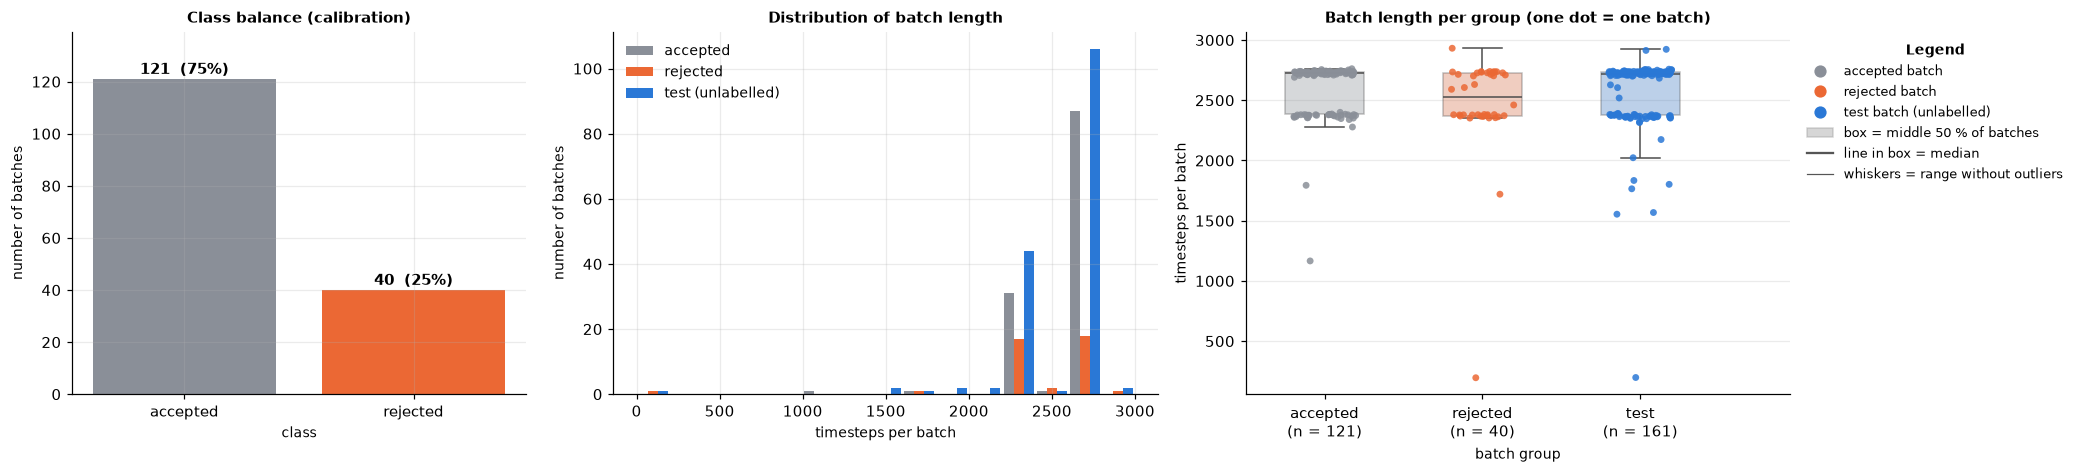

In [2]:
fig,ax=plt.subplots(1,3,figsize=(19,4.4),gridspec_kw=dict(width_ratios=[1,1.2,1.2]))
vc=y.value_counts().reindex(["accepted","rejected"]); ax[0].bar(vc.index,vc.values,color=[PAL[k] for k in vc.index])
for i,v in enumerate(vc.values): ax[0].text(i,v+2,f"{v}  ({100*v/vc.sum():.0f}%)",ha="center",fontweight="bold")
ax[0].set(title="Class balance (calibration)",xlabel="class",ylabel="number of batches",ylim=(0,vc.max()*1.15))
length_panels(ax[1],ax[2],n_cal,n_test,y,bins=np.arange(0,3200,200))
plt.tight_layout(); plt.show()

## 2. Every variable over (normalised) time
Do accepted and rejected batches follow different trajectories?
Time is rescaled to 0–1 because batches have different lengths, and curves are lightly smoothed (9-point moving average). **Grey band** = middle 80 % of accepted batches, **black line** = accepted median, **thin orange** = each rejected batch, **violet dashed** = rejected median. The y-axis is zoomed to the 1st–99th percentile, so extreme outliers run off the plot (they are shown in §5).

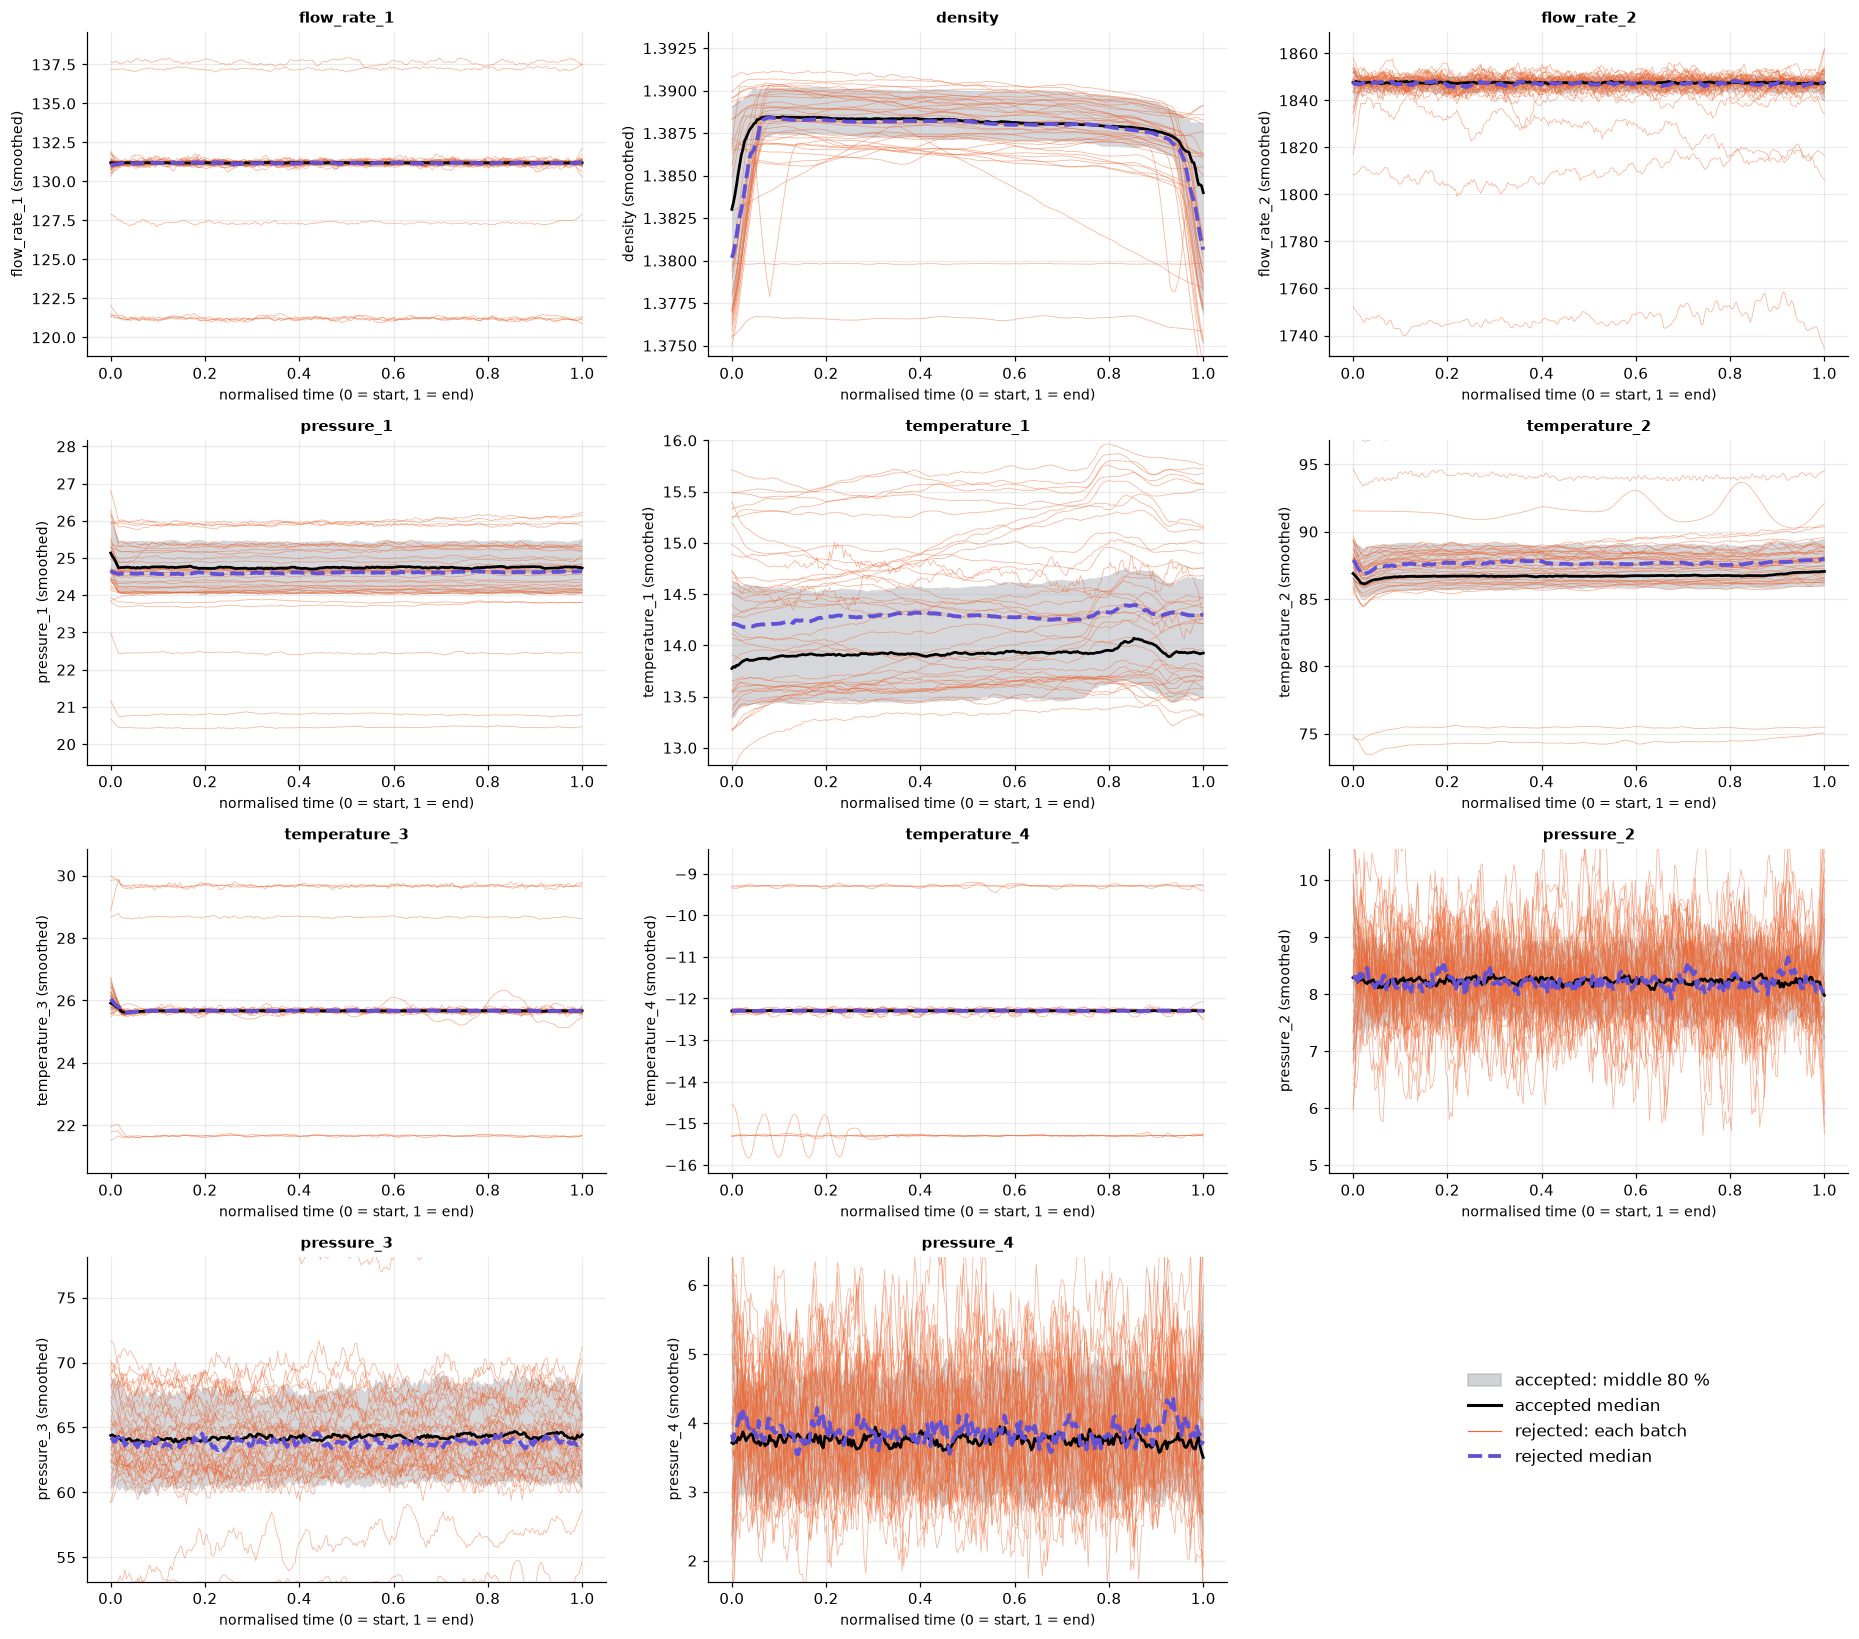

In [3]:
fig,axs=plt.subplots(4,3,figsize=(17,15))
for ax,v in zip(axs.ravel(),V):
    X=sm(Xc[v]); ax.fill_between(g,np.percentile(X[acc],10,axis=0),np.percentile(X[acc],90,axis=0),color=ACC,alpha=.35,lw=0)
    for r in X[rej]: ax.plot(g,r,color=REJ,lw=.5,alpha=.5)
    ax.plot(g,np.median(X[acc],axis=0),color="#000000",lw=1.8); ax.plot(g,np.median(X[rej],axis=0),color=REJ_MED,lw=2.5,ls="--")
    ax.set_ylim(*robust_ylim(X)); ax.set(title=v,xlabel="normalised time (0 = start, 1 = end)",ylabel=f"{v} (smoothed)")
legend_axis(axs.ravel()[-1],[patch(ACC,"accepted: middle 80 %"),line("#000000","accepted median"),line(REJ,"rejected: each batch",lw=.8),line(REJ_MED,"rejected median",lw=2.5,ls="--")])
plt.tight_layout(); plt.show()

## 3. Does the *level* of a variable separate the classes?
One dot per batch = the batch's median over the whole run; boxes show the spread of each class. If the orange dots sit outside the grey ones, the level alone flags those batches. When a few extreme batches would squash the others, the axis is zoomed to the bulk and those batches are drawn as **triangles at the edge** (▲ above, ▼ below) with their number and most extreme value. Exact values of all outliers are in §5.

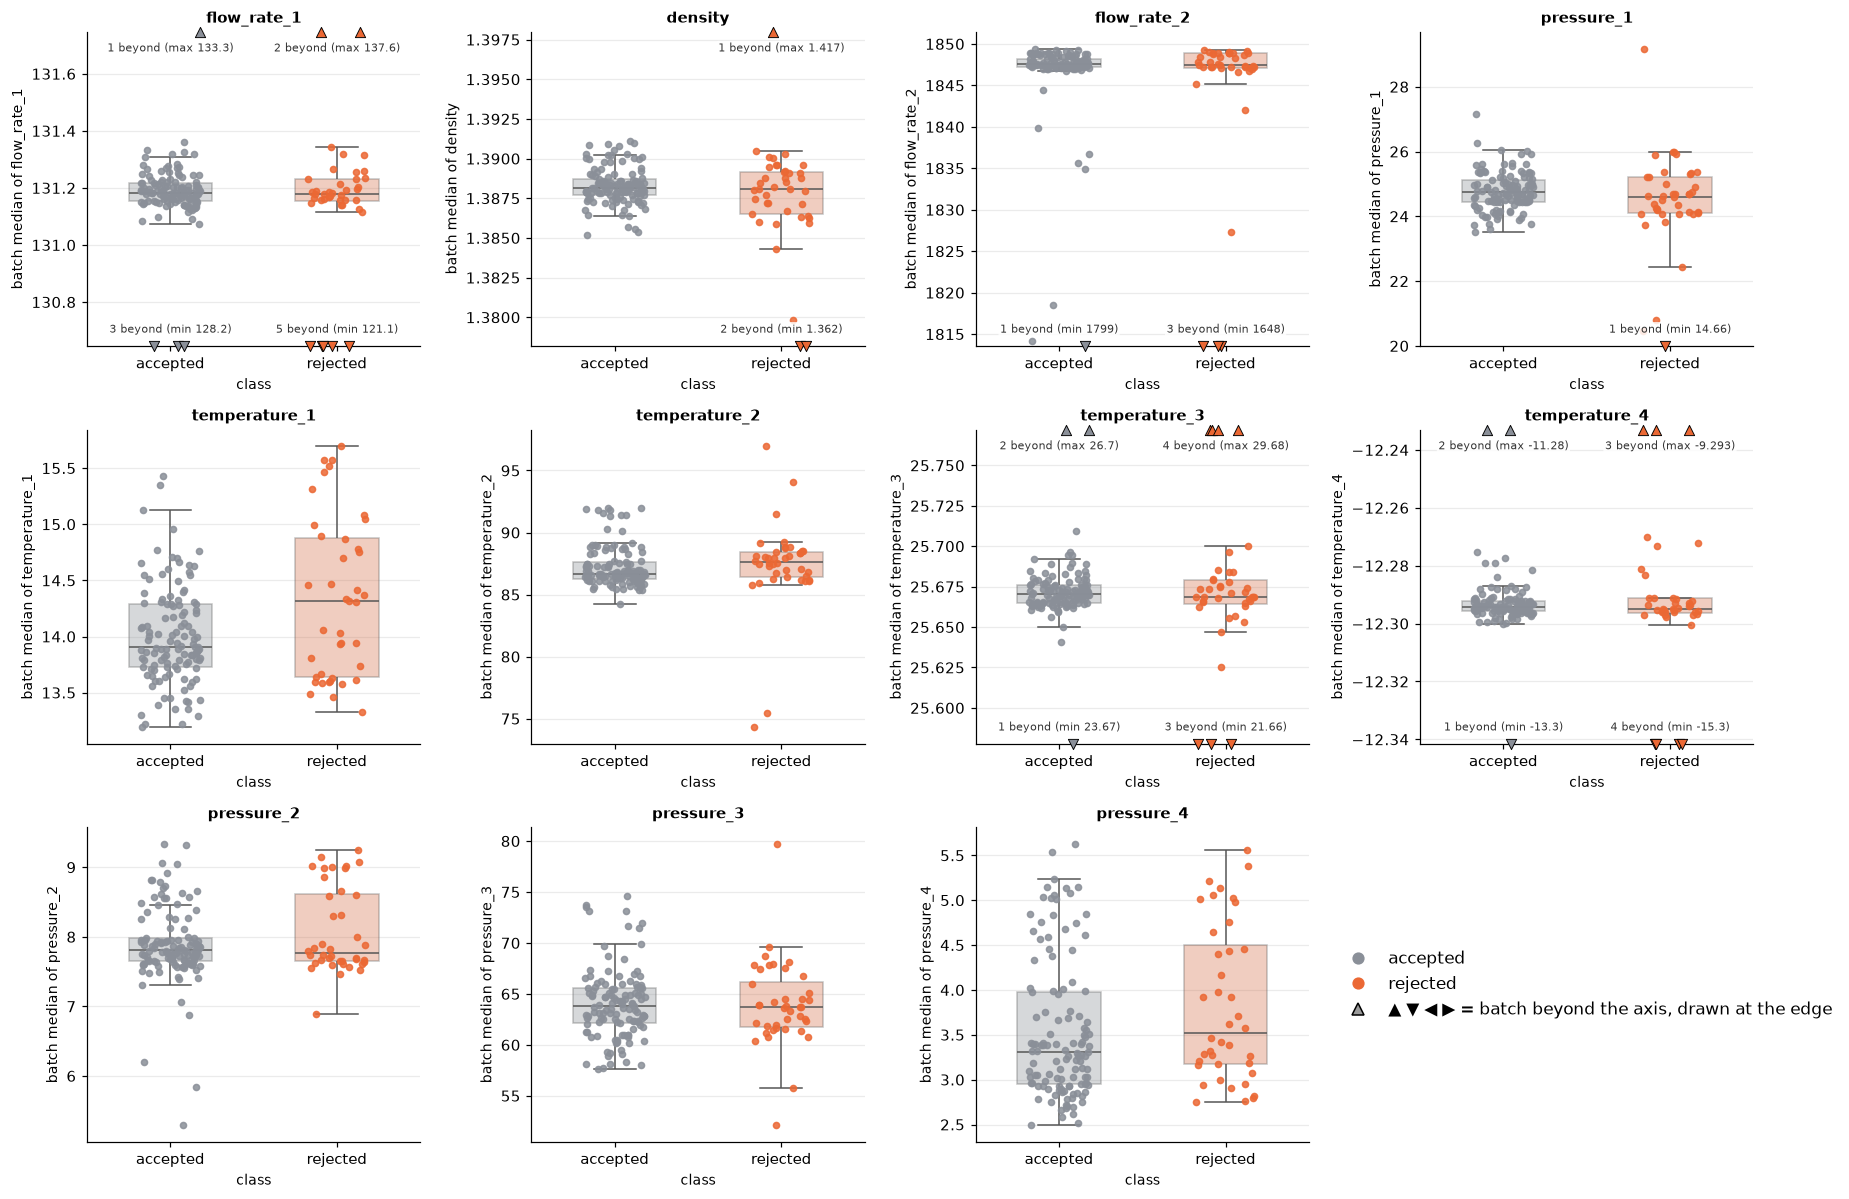

In [4]:
fig,axs=plt.subplots(3,4,figsize=(17,11)); off=False
for ax,v in zip(axs.ravel(),V):
    off|=class_box(ax,med[v].values,yc,f"batch median of {v}"); ax.set_title(v)
legend_axis(axs.ravel()[-1],CLASS_LEG+[OFF_LEG]*off); plt.tight_layout(); plt.show()

## 4. Does the *noisiness* of a variable separate the classes?
One dot per batch = the within-batch standard deviation (log scale). A higher orange cloud means rejected batches are noisier in that variable. When a few extreme batches would squash the others, the axis is zoomed to the bulk and those batches are drawn as **triangles at the edge** (▲ above, ▼ below) with their number and most extreme value.

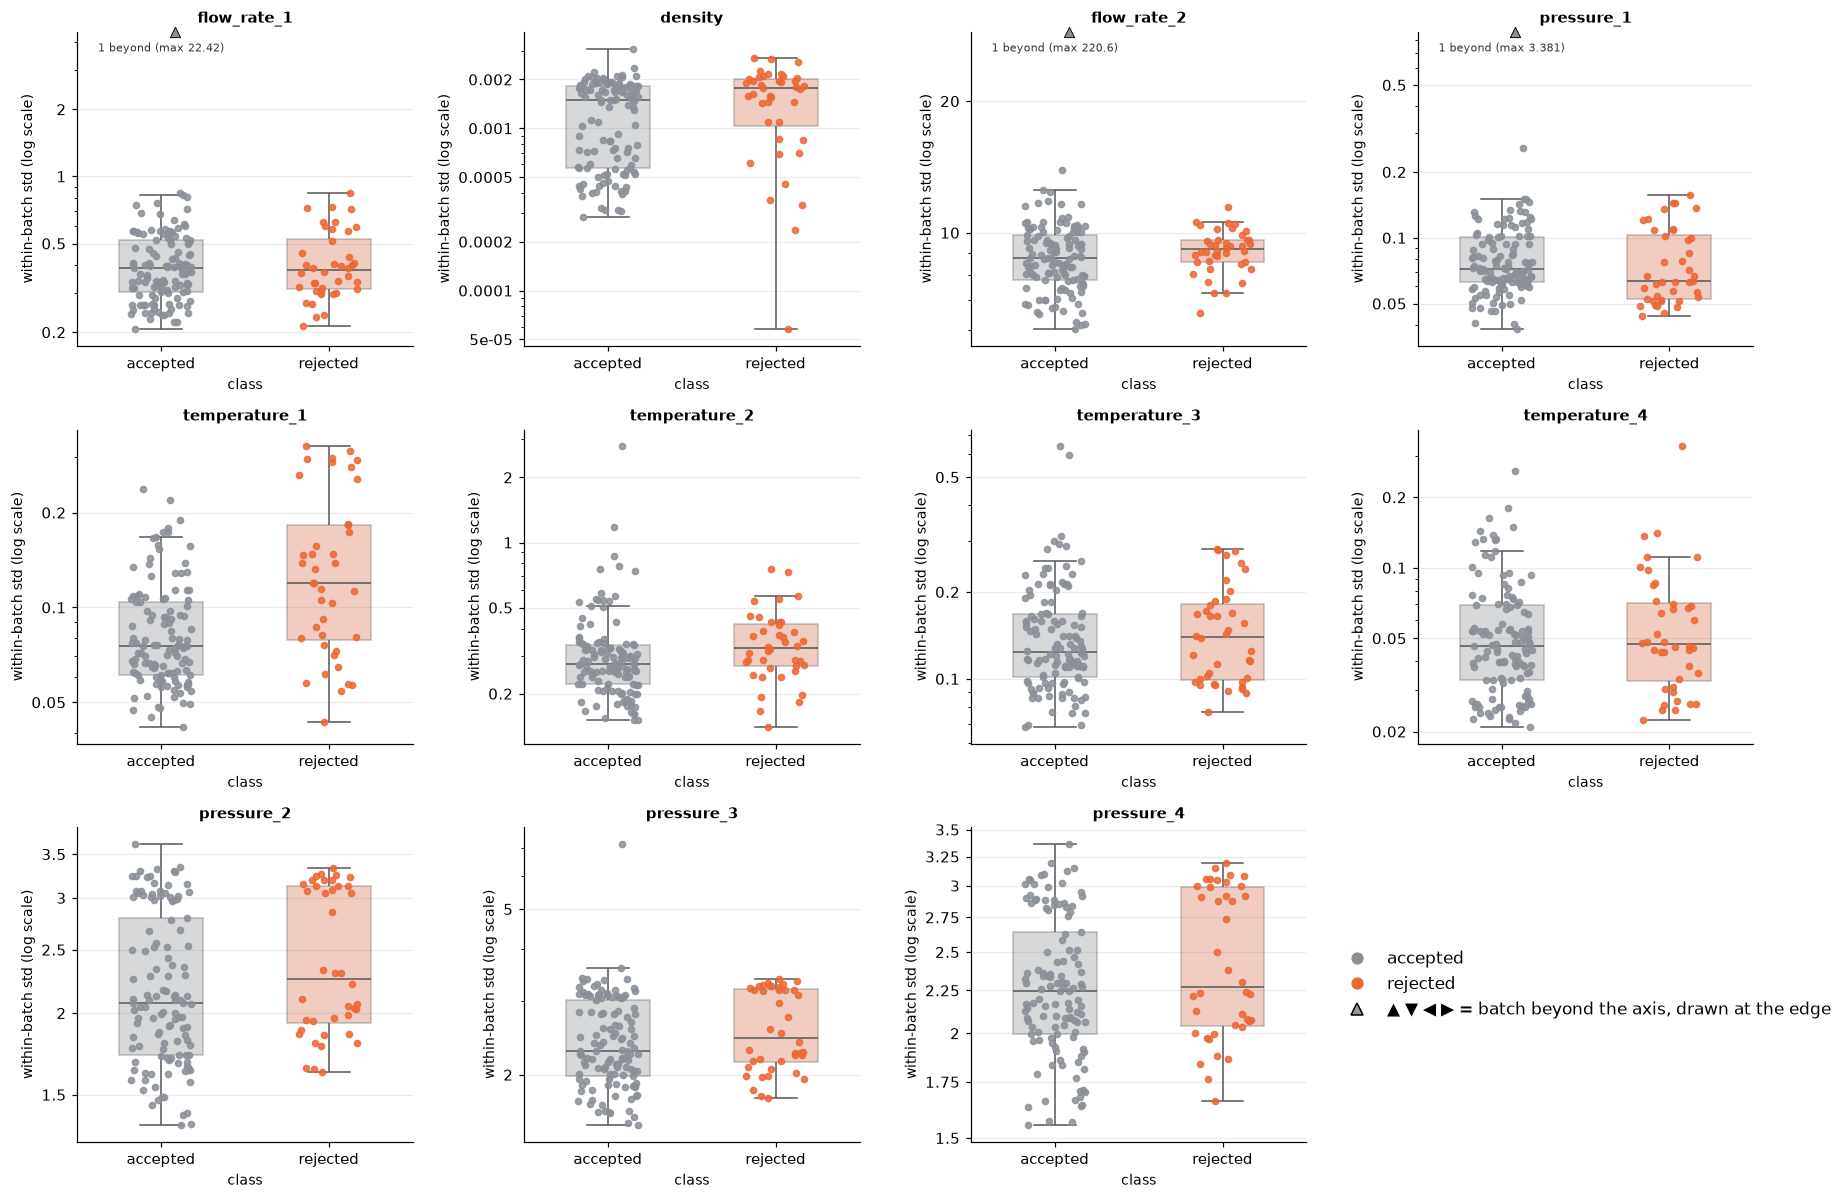

In [5]:
fig,axs=plt.subplots(3,4,figsize=(17,11)); off=False
for ax,v in zip(axs.ravel(),V):
    off|=class_box(ax,sd[v].values,yc,"within-batch std (log scale)",log=True); ax.set_title(v)
legend_axis(axs.ravel()[-1],CLASS_LEG+[OFF_LEG]*off); plt.tight_layout(); plt.show()

## 5. Which batches are outliers, and in which variable?
Each cell = |batch median − accepted centre| / threshold, where the threshold is the largest deviation seen among accepted batches (the baseline rule). **Values above 1 (dark) are outside anything seen in accepted batches.** Rows: rejected batches on top, accepted below, each sorted by their largest deviation.

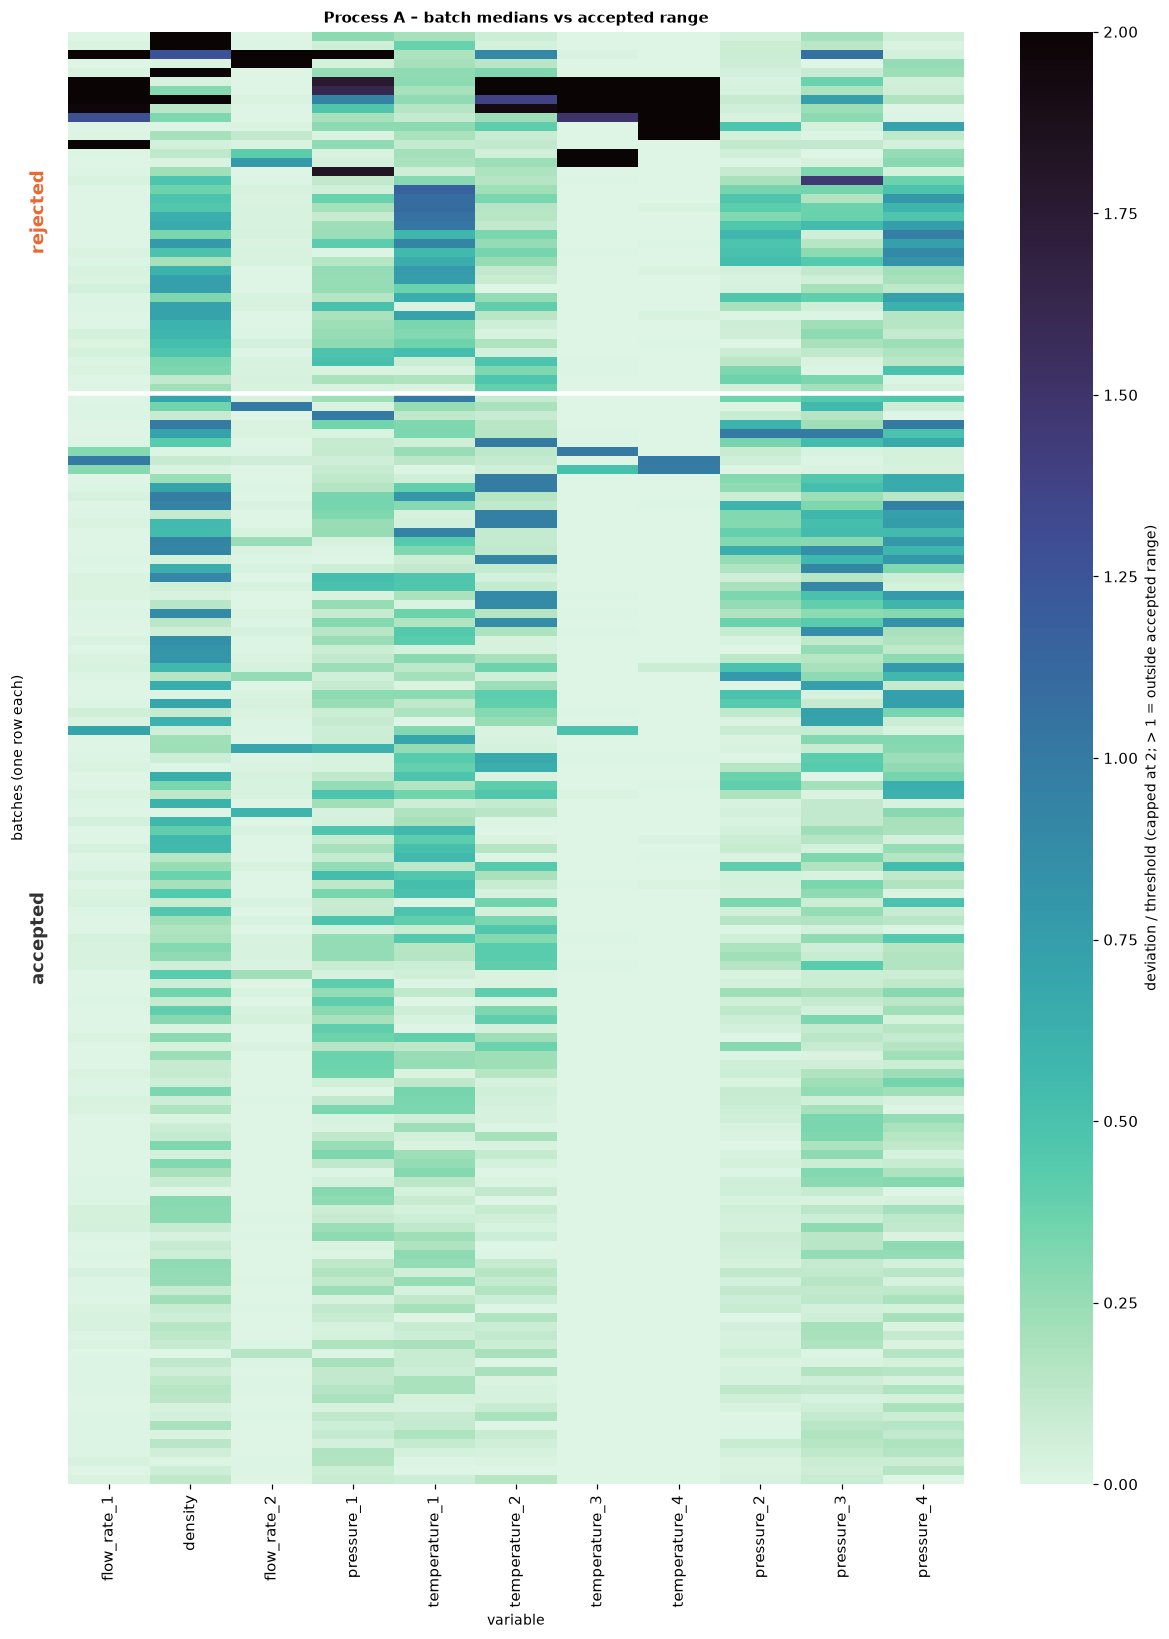

rejected flagged: 22/40 | accepted flagged (in-sample, 0 by construction): 0/121


In [6]:
centre=med[acc].median(); thr=(med[acc]-centre).abs().max()
dev=(med-centre).abs()/thr
order=list(dev[rej].max(axis=1).sort_values(ascending=False).index)+list(dev[acc].max(axis=1).sort_values(ascending=False).index)
fig,ax=plt.subplots(1,1,figsize=(11,15))
sns.heatmap(dev.loc[order].clip(upper=2),cmap="mako_r",vmin=0,vmax=2,ax=ax,cbar_kws=dict(label="deviation / threshold (capped at 2; > 1 = outside accepted range)"),yticklabels=False,linewidths=0)
ax.axhline(rej.sum(),color="white",lw=3)
ax.text(-.25,rej.sum()/2,"rejected",rotation=90,va="center",ha="right",color=REJ,fontweight="bold",fontsize=12)
ax.text(-.25,rej.sum()+acc.sum()/2,"accepted",rotation=90,va="center",ha="right",color=INK,fontweight="bold",fontsize=12)
ax.set_title("Process A – batch medians vs accepted range"); ax.set_xlabel("variable"); ax.set_ylabel("batches (one row each)",labelpad=28); ax.grid(False)
plt.tight_layout(); plt.show()
flag=(dev>1).any(axis=1)
print(f"rejected flagged: {flag[rej].sum()}/{rej.sum()} | accepted flagged (in-sample, 0 by construction): {flag[acc].sum()}/{acc.sum()}")

## 6. Batch order: drift over the campaign?
If the process drifted (sensor ageing, raw-material lots), batch number would show structure.
- **Top:** where accepted, test and rejected batches fall in the batch sequence (one tick per batch).
- **Middle:** rolling share of rejected batches (dashed = overall rate).
- **Bottom grid:** batch median of every variable against batch number. When a few extreme batches would squash the others, the axis is zoomed to the bulk and those batches are drawn as **triangles at the edge** (▲ above, ▼ below) with their number and most extreme value.

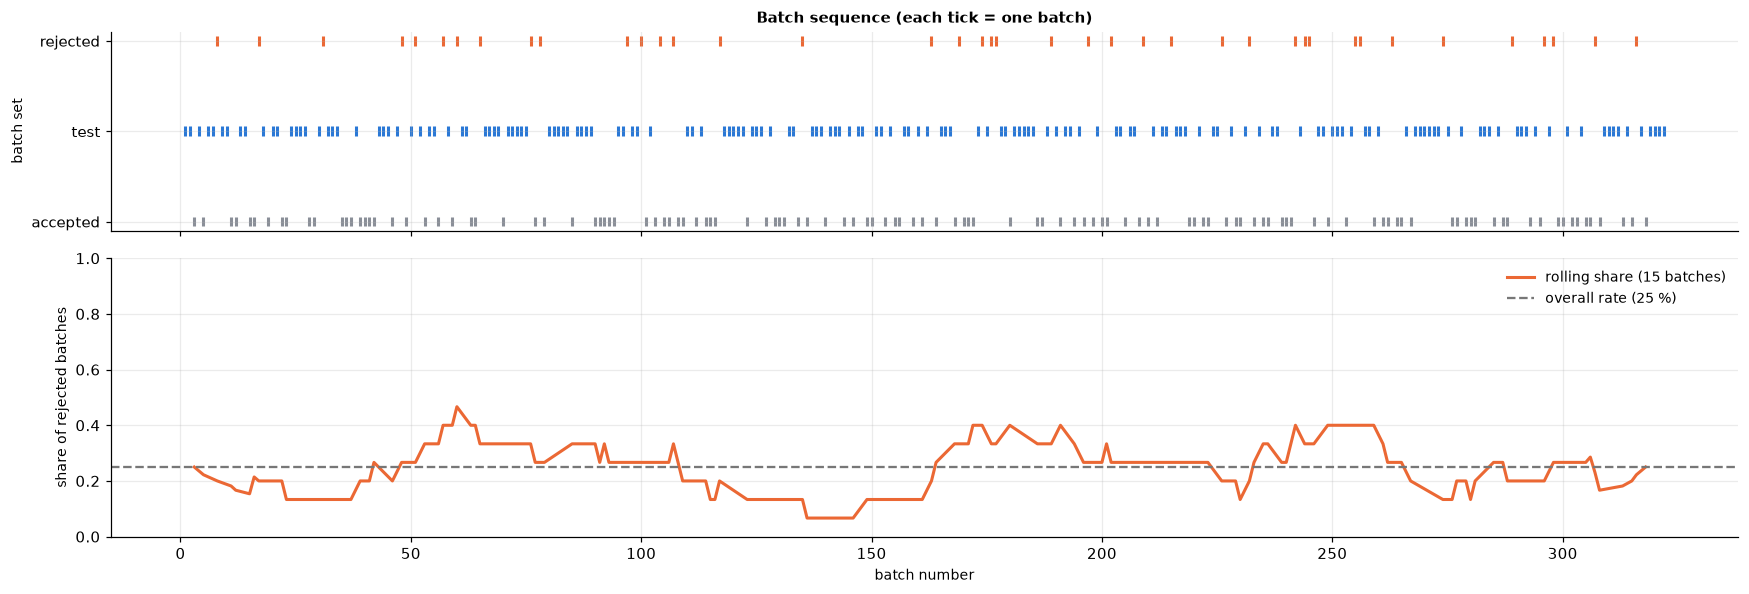

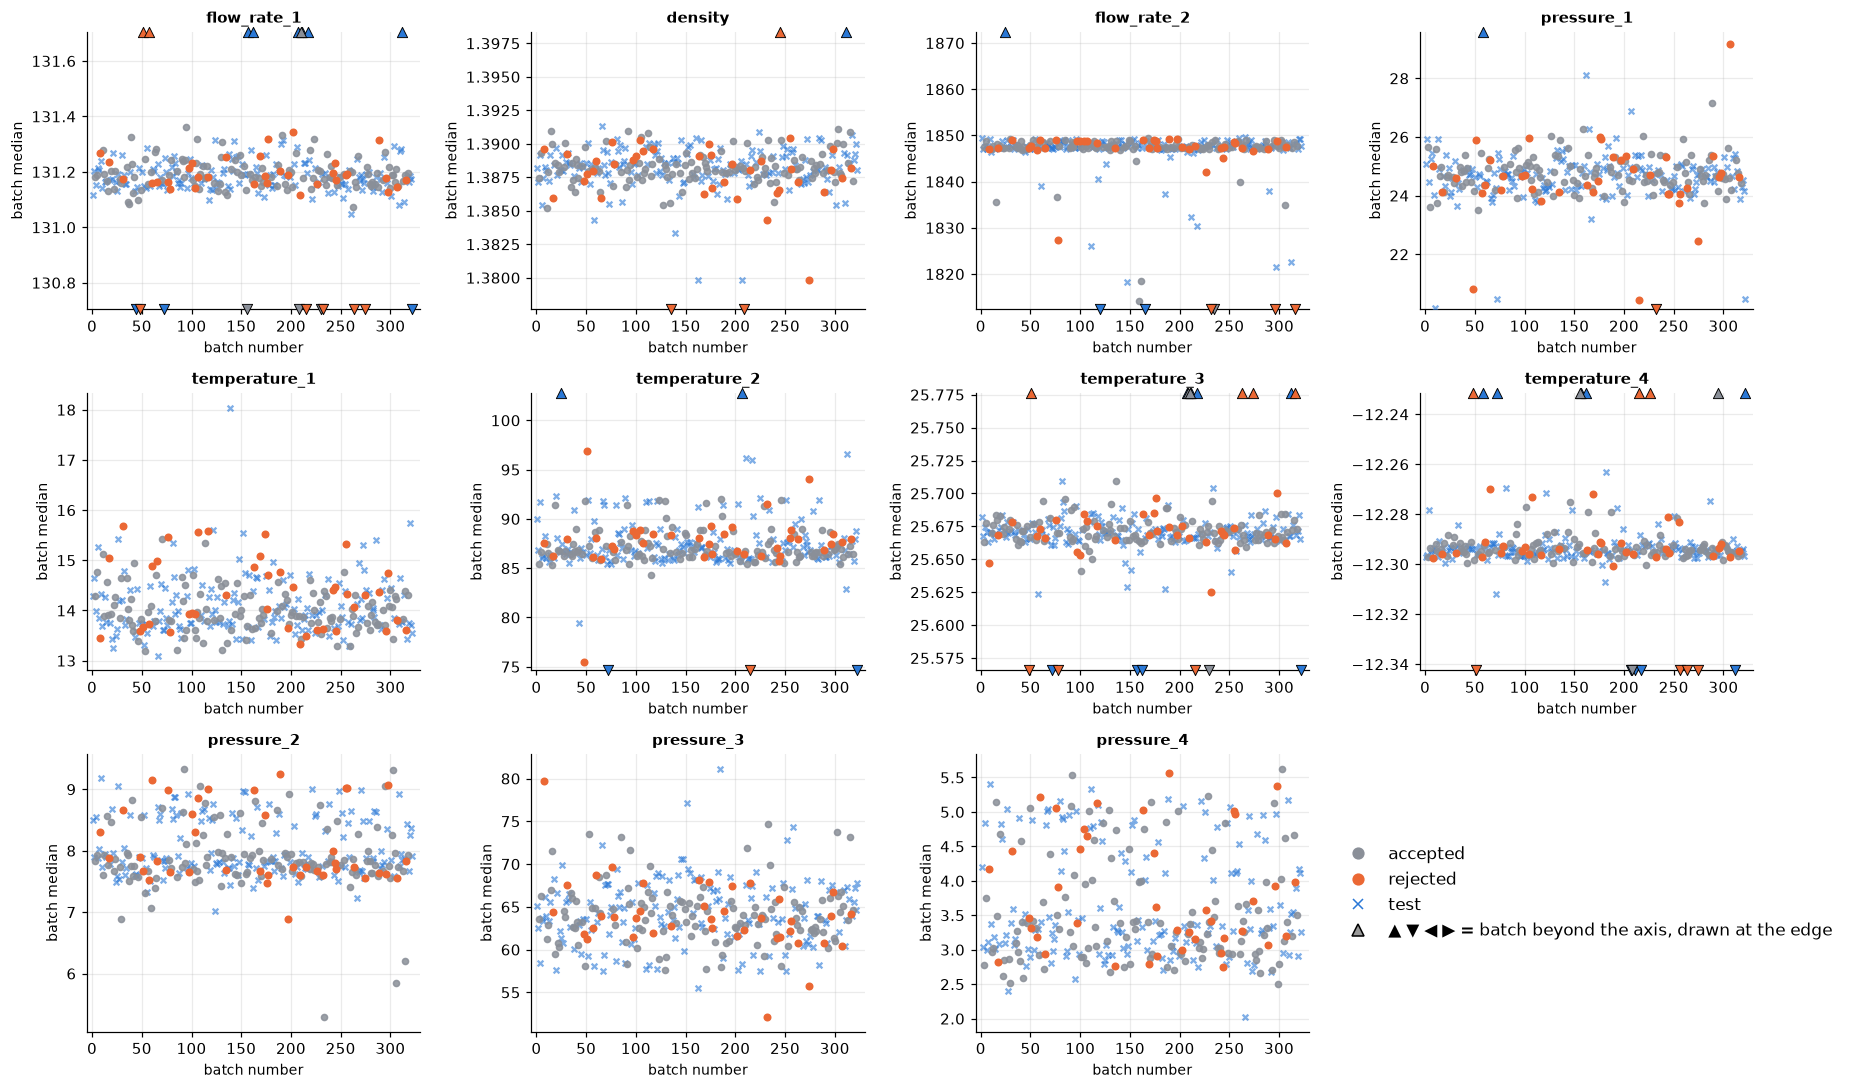

In [7]:
bn=bnum(ids); o=np.argsort(bn); tb=bnum(idst)
fig,ax=plt.subplots(2,1,figsize=(16,5.5),sharex=True,gridspec_kw=dict(height_ratios=[1,1.4]))
ax[0].scatter(bn,np.where(rej,1,0),c=np.where(rej,REJ,ACC),s=40,marker="|",linewidths=2)
ax[0].scatter(tb,np.full(len(tb),.5),c=TEST,s=40,marker="|",linewidths=2)
ax[0].set_yticks([0,.5,1],["accepted","test","rejected"]); ax[0].set_ylabel("batch set"); ax[0].set_title("Batch sequence (each tick = one batch)")
w=15; rr=pd.Series(rej[o].astype(float)).rolling(w,center=True,min_periods=5).mean()
ax[1].plot(bn[o],rr,color=REJ,lw=2,label=f"rolling share ({w} batches)"); ax[1].axhline(rej.mean(),color="#777",ls="--",label=f"overall rate ({100*rej.mean():.0f} %)")
ax[1].set(ylabel="share of rejected batches",xlabel="batch number",ylim=(0,1)); ax[1].legend(loc="upper right")
plt.tight_layout(); plt.show()
fig,axs=plt.subplots(3,4,figsize=(17,10)); off=False; xl=(-5,330)
for ax,v in zip(axs.ravel(),V):
    lo,hi,_=bulk_lims(pd.concat([med[v],tmed[v]]))
    off|=scatter_clip(ax,tb,tmed[v],xl,(lo,hi),TEST,s=14,marker="x",alpha=.6)[2]
    off|=scatter_clip(ax,bn[acc],med[v][acc],xl,(lo,hi),ACC,s=16,alpha=.85)[2]
    off|=scatter_clip(ax,bn[rej],med[v][rej],xl,(lo,hi),REJ,s=18)[2]
    ax.set_xlim(*xl); ax.set_ylim(lo,hi); ax.set(title=v,xlabel="batch number",ylabel="batch median")
legend_axis(axs.ravel()[-1],CLASS_LEG+[dot(TEST,"test","x")]+[OFF_LEG]*off)
plt.tight_layout(); plt.show()

## 7. Batches 101–104 up close
How do these four neighbouring batches compare with the rest? Faint lines = all other batches (grey accepted, orange rejected); the four batches are drawn on top, each with its own colour and line style. `A_102` is a test batch (no label). Curves are smoothed.

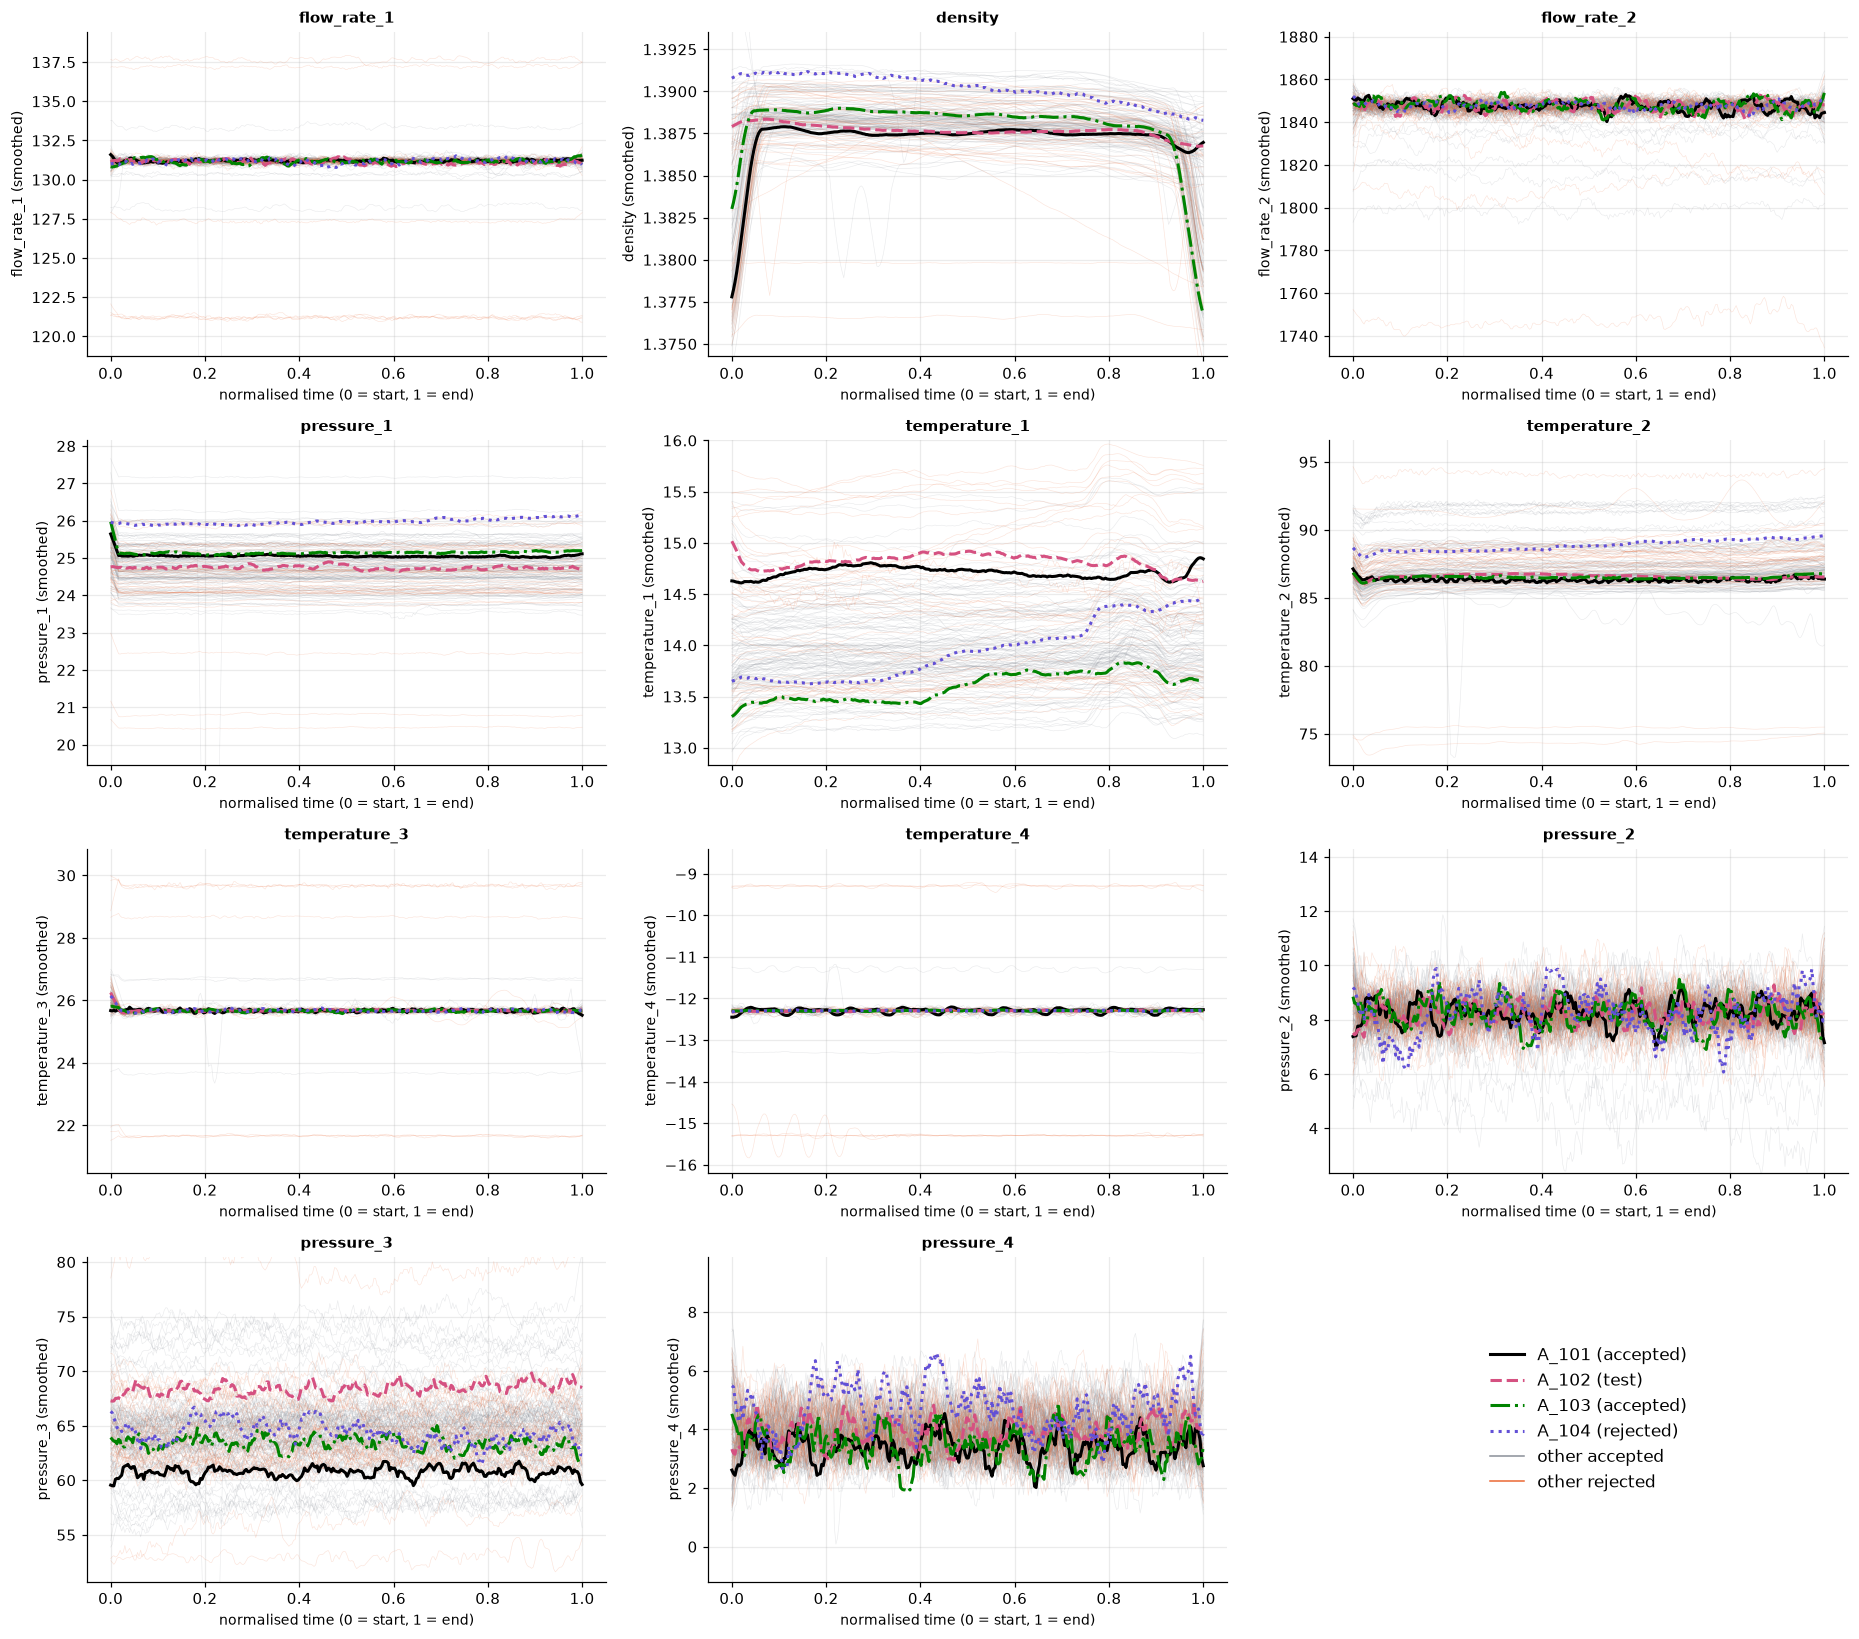

In [8]:
HL=["A_101","A_102","A_103","A_104"]
lab_of=lambda b: f"{b} ({y[b]})" if b in ids else f"{b} (test)"
fig,axs=plt.subplots(4,3,figsize=(17,15))
for ax,v in zip(axs.ravel(),V):
    X=sm(Xc[v])
    for k,c in ((acc,ACC),(rej,REJ)):
        for r in X[k]: ax.plot(g,r,color=c,lw=.4,alpha=.18)
    for i,b in enumerate(HL):
        s=X[ids.index(b)] if b in ids else sm(Xt[v])[idst.index(b)]
        ax.plot(g if b in ids else gt,s,color=HL_COL[i],ls=HL_LS[i],lw=2)
    ax.set_ylim(*robust_ylim(Xc[v])); ax.set(title=v,xlabel="normalised time (0 = start, 1 = end)",ylabel=f"{v} (smoothed)")
legend_axis(axs.ravel()[-1],[line(HL_COL[i],lab_of(b),ls=HL_LS[i]) for i,b in enumerate(HL)]+[line(ACC,"other accepted",lw=1),line(REJ,"other rejected",lw=1)])
plt.tight_layout(); plt.show()

## 8. Batches in feature space (PCA)
Each batch is summarised by the median, standard deviation and trend (slope over normalised time) of every variable, robust-scaled, then projected to 2D. If the classes formed separate clouds, a simple model would have something easy to learn. Batches 101–104 are ringed. The axes are zoomed on the dense centre; far-away batches are drawn as triangles at the edge, pointing towards where they are.

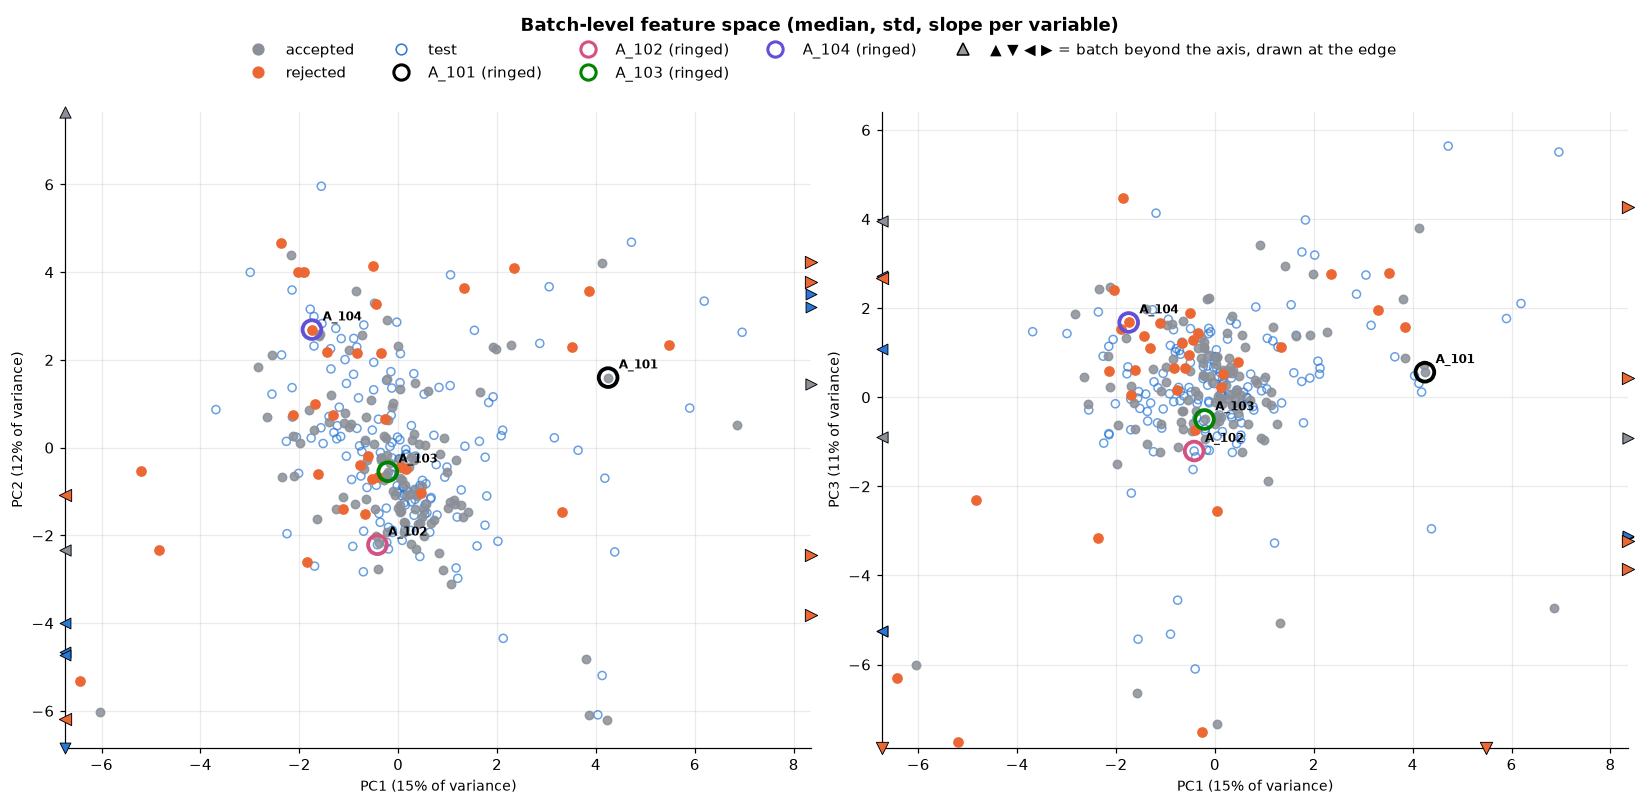

Top loadings


,PC1,PC2,PC3
temperature_4_med,0.58,0.36,0.27
temperature_3_med,-0.56,-0.17,0.01
flow_rate_1_med,-0.29,-0.07,0.54
flow_rate_2_slope,-0.26,0.42,-0.51
temperature_2_med,-0.23,0.03,-0.01
flow_rate_2_med,-0.18,0.21,0.41
pressure_1_med,-0.12,-0.09,0.23
temperature_3_std,-0.12,0.27,-0.03


In [9]:
def feats(df):
    gb=df.groupby("batch_id"); f=pd.concat([gb[V].median().add_suffix("_med"),gb[V].std().add_suffix("_std")],axis=1)
    sl=df.groupby("batch_id").apply(lambda x:pd.Series({v+"_slope":np.polyfit(x.tn,x[v],1)[0] for v in V}),include_groups=False)
    f=f.join(sl); f["len"]=gb.size(); return f
Fc=feats(cal).loc[ids]; Ft=feats(test).loc[idst]
sc=RobustScaler().fit(Fc); Zc=np.clip(sc.transform(Fc),-8,8); Zt=np.clip(sc.transform(Ft),-8,8)
pca=PCA(3).fit(Zc); Pc,Pt=pca.transform(Zc),pca.transform(Zt)
fig,ax=plt.subplots(1,2,figsize=(15,6.5)); off=False
for a,(i,j) in zip(ax,[(0,1),(0,2)]):
    xl=bulk_lims(np.r_[Pc[:,i],Pt[:,i]],k=.5,force=True)[:2]; yl=bulk_lims(np.r_[Pc[:,j],Pt[:,j]],k=.5,force=True)[:2]
    off|=scatter_clip(a,Pt[:,i],Pt[:,j],xl,yl,TEST,s=28,hollow_=True,alpha=.7)[2]
    off|=scatter_clip(a,Pc[acc,i],Pc[acc,j],xl,yl,ACC,s=30,alpha=.85)[2]; off|=scatter_clip(a,Pc[rej,i],Pc[rej,j],xl,yl,REJ,s=36)[2]
    for n,b in enumerate(HL):
        P,k=(Pc,ids.index(b)) if b in ids else (Pt,idst.index(b))
        px,py=np.clip(P[k,i],*xl),np.clip(P[k,j],*yl)
        a.scatter(px,py,s=150,facecolors="none",edgecolors=HL_COL[n],lw=2.5,zorder=6)
        a.annotate(b,(px,py),xytext=(7,6),textcoords="offset points",fontweight="bold",fontsize=8)
    a.set_xlim(*xl); a.set_ylim(*yl)
    a.set_xlabel(f"PC{i+1} ({100*pca.explained_variance_ratio_[i]:.0f}% of variance)"); a.set_ylabel(f"PC{j+1} ({100*pca.explained_variance_ratio_[j]:.0f}% of variance)")
plt.tight_layout(); top_legend(fig,CLASS_LEG+[hollow(TEST,"test")]+[Line2D([],[],marker="o",ls="",markerfacecolor="none",markeredgecolor=HL_COL[n],markeredgewidth=2,markersize=10,label=f"{b} (ringed)") for n,b in enumerate(HL)]+[OFF_LEG]*off,ncol=5,
           title="Batch-level feature space (median, std, slope per variable)",title_fontproperties=dict(weight="bold",size=12)); plt.show()
load_=pd.DataFrame(pca.components_.T,index=Fc.columns,columns=["PC1","PC2","PC3"]); print("Top loadings"); display(load_.reindex(load_.PC1.abs().sort_values(ascending=False).index).head(8).round(2))

## 9. Which summary features separate the classes best?
Features are named `variable_summary`: `_med` = batch median, `_std` = within-batch standard deviation, `_slope` = trend over the run, `len` = number of timesteps.
- **Left:** AUC of every per-batch feature on its own (0.5 = no information, 1 = perfect separation; direction ignored), top 15.
- **Right:** the batches plotted on the two best features.

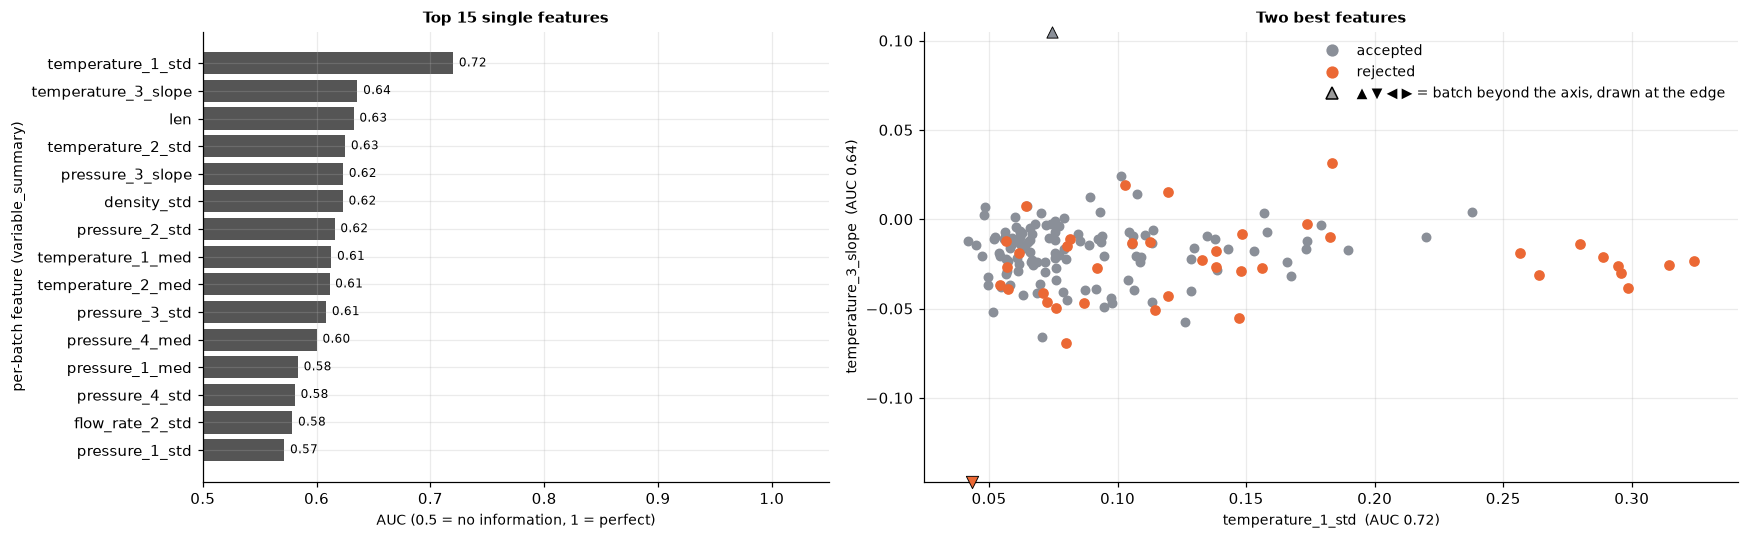

In [10]:
auc=pd.Series({c:roc_auc_score(rej,Fc[c]) for c in Fc.columns}); auc=(auc-.5).abs()+.5
top=auc.sort_values(ascending=False).head(15)
fig,ax=plt.subplots(1,2,figsize=(16,5),gridspec_kw=dict(width_ratios=[1,1.3]))
ax[0].barh(top.index[::-1],top.values[::-1],color="#555"); ax[0].set_xlim(.5,1.05)
for yy,v in enumerate(top.values[::-1]): ax[0].text(v+.005,yy,f"{v:.2f}",va="center",fontsize=8)
ax[0].set(title="Top 15 single features",xlabel="AUC (0.5 = no information, 1 = perfect)",ylabel="per-batch feature (variable_summary)")
best=list(top.index[:2]); xl=bulk_lims(Fc[best[0]])[:2]; yl=bulk_lims(Fc[best[1]])[:2]
o1=scatter_clip(ax[1],Fc.loc[acc,best[0]],Fc.loc[acc,best[1]],xl,yl,ACC,s=30)[2]; o2=scatter_clip(ax[1],Fc.loc[rej,best[0]],Fc.loc[rej,best[1]],xl,yl,REJ,s=36)[2]
ax[1].set_xlim(*xl); ax[1].set_ylim(*yl)
ax[1].set(xlabel=f"{best[0]}  (AUC {auc[best[0]]:.2f})",ylabel=f"{best[1]}  (AUC {auc[best[1]]:.2f})",title="Two best features"); ax[1].legend(handles=CLASS_LEG+[OFF_LEG]*(o1 or o2),loc="upper right")
plt.tight_layout(); plt.show()

## 10. Relationships between variables
Spearman correlation between variables (blue = negative, red = positive). **Left:** over all timesteps (moment-to-moment co-movement). **Right:** over batch medians (do batches with a high level in one variable also have a high level in another?).

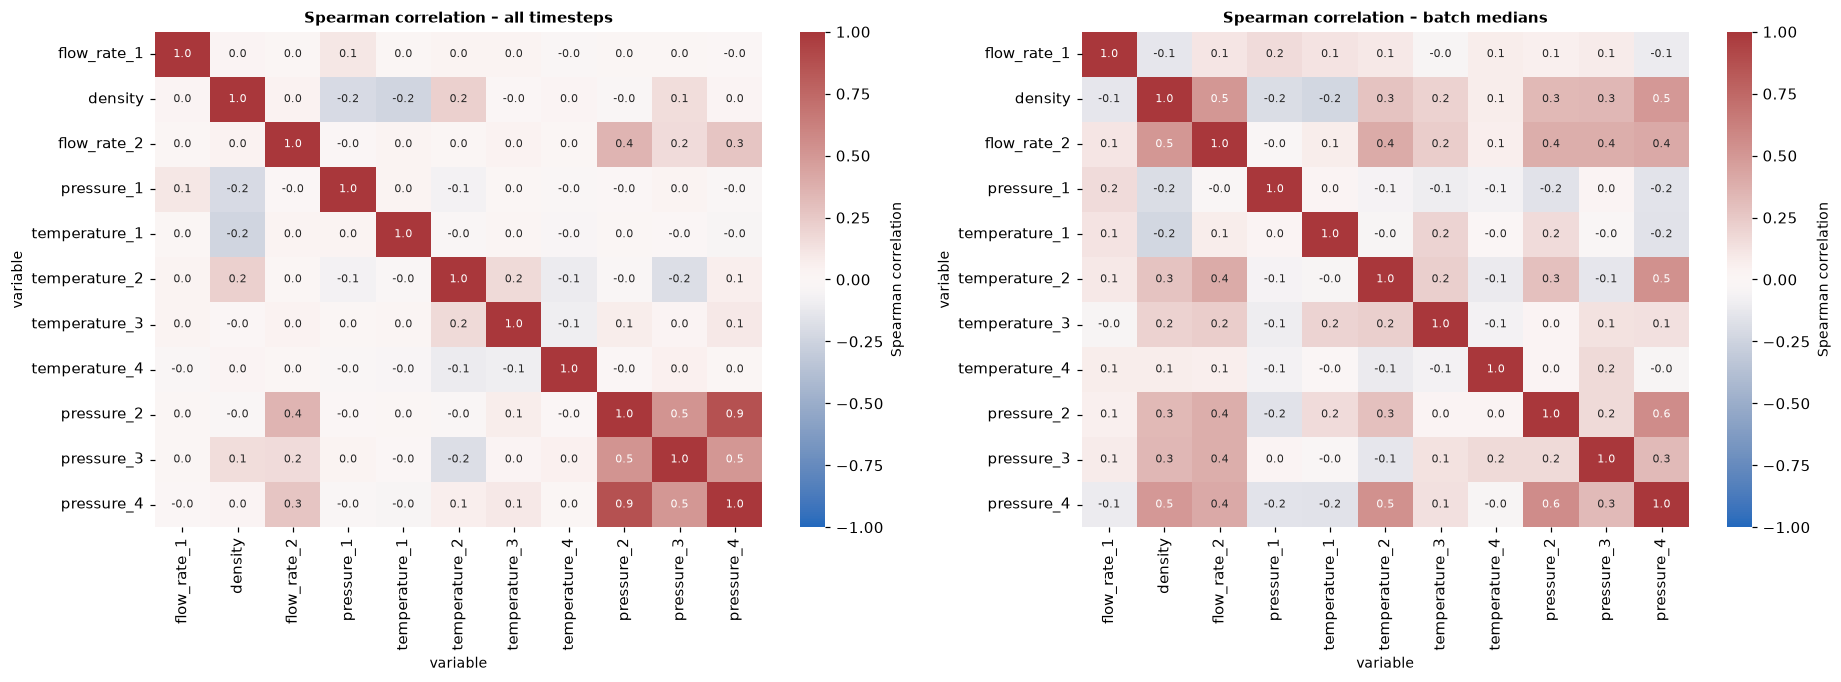

In [11]:
fig,ax=plt.subplots(1,2,figsize=(17,6.3))
sub=cal.sample(60000,random_state=0)[V]
sns.heatmap(sub.corr(method="spearman"),cmap="vlag",center=0,vmin=-1,vmax=1,annot=True,fmt=".1f",annot_kws=dict(size=7),ax=ax[0],cbar_kws=dict(label="Spearman correlation")); ax[0].set_title("Spearman correlation – all timesteps")
sns.heatmap(med.corr(method="spearman"),cmap="vlag",center=0,vmin=-1,vmax=1,annot=True,fmt=".1f",annot_kws=dict(size=7),ax=ax[1],cbar_kws=dict(label="Spearman correlation")); ax[1].set_title("Spearman correlation – batch medians")
for a in ax: a.set(xlabel="variable",ylabel="variable"); a.grid(False)
plt.tight_layout(); plt.show()

## 11. Calibration vs test: same distribution?
Batch medians are put on a common scale (robust z-score: minus the calibration median, divided by the calibration IQR). If test boxes (blue) sat far from calibration boxes (grey), a model trained on calibration could fail on test.

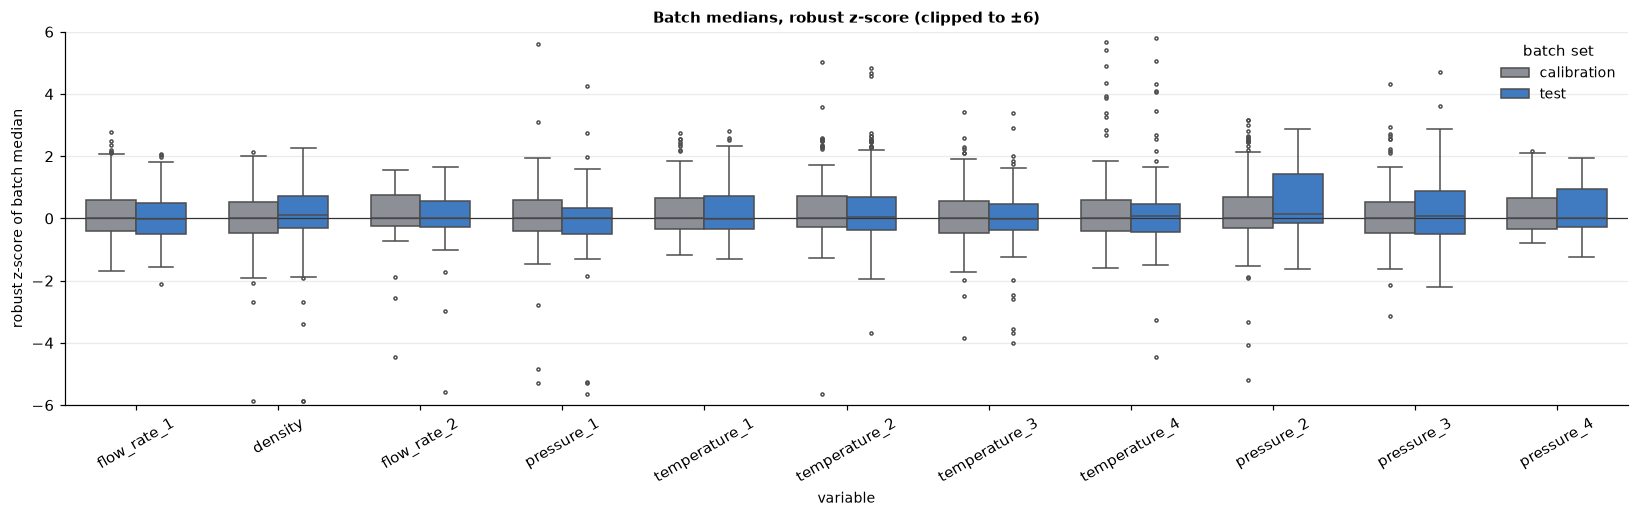

In [12]:
ctr=med.median(); iqr=(med.quantile(.75)-med.quantile(.25)); zc=(med-ctr)/iqr; zt=(tmed-ctr)/iqr
d=pd.concat([zc.assign(set="calibration"),zt.assign(set="test")]).melt(id_vars="set",var_name="variable",value_name="z")
fig,ax=plt.subplots(figsize=(15,4.8)); sns.boxplot(data=d,x="variable",y="z",hue="set",palette={"calibration":ACC,"test":TEST},ax=ax,fliersize=2,width=.7)
ax.set_ylim(-6,6); ax.axhline(0,color=INK,lw=.8); ax.set(title="Batch medians, robust z-score (clipped to ±6)",xlabel="variable",ylabel="robust z-score of batch median")
ax.legend(title="batch set",loc="upper right"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

## 12. Unusual batches up close
The four shortest calibration batches against the accepted range (grey band = 5–95 % of accepted batches, grey dashed line = accepted median). Curves are lightly smoothed (moving average over ~1 % of each batch) so noisy variables such as `pressure_3` show the level instead of a solid band of noise.

{'A_232': (196, 'rejected'), 'A_149': (1166, 'accepted'), 'A_215': (1720, 'rejected'), 'A_285': (1794, 'accepted')}


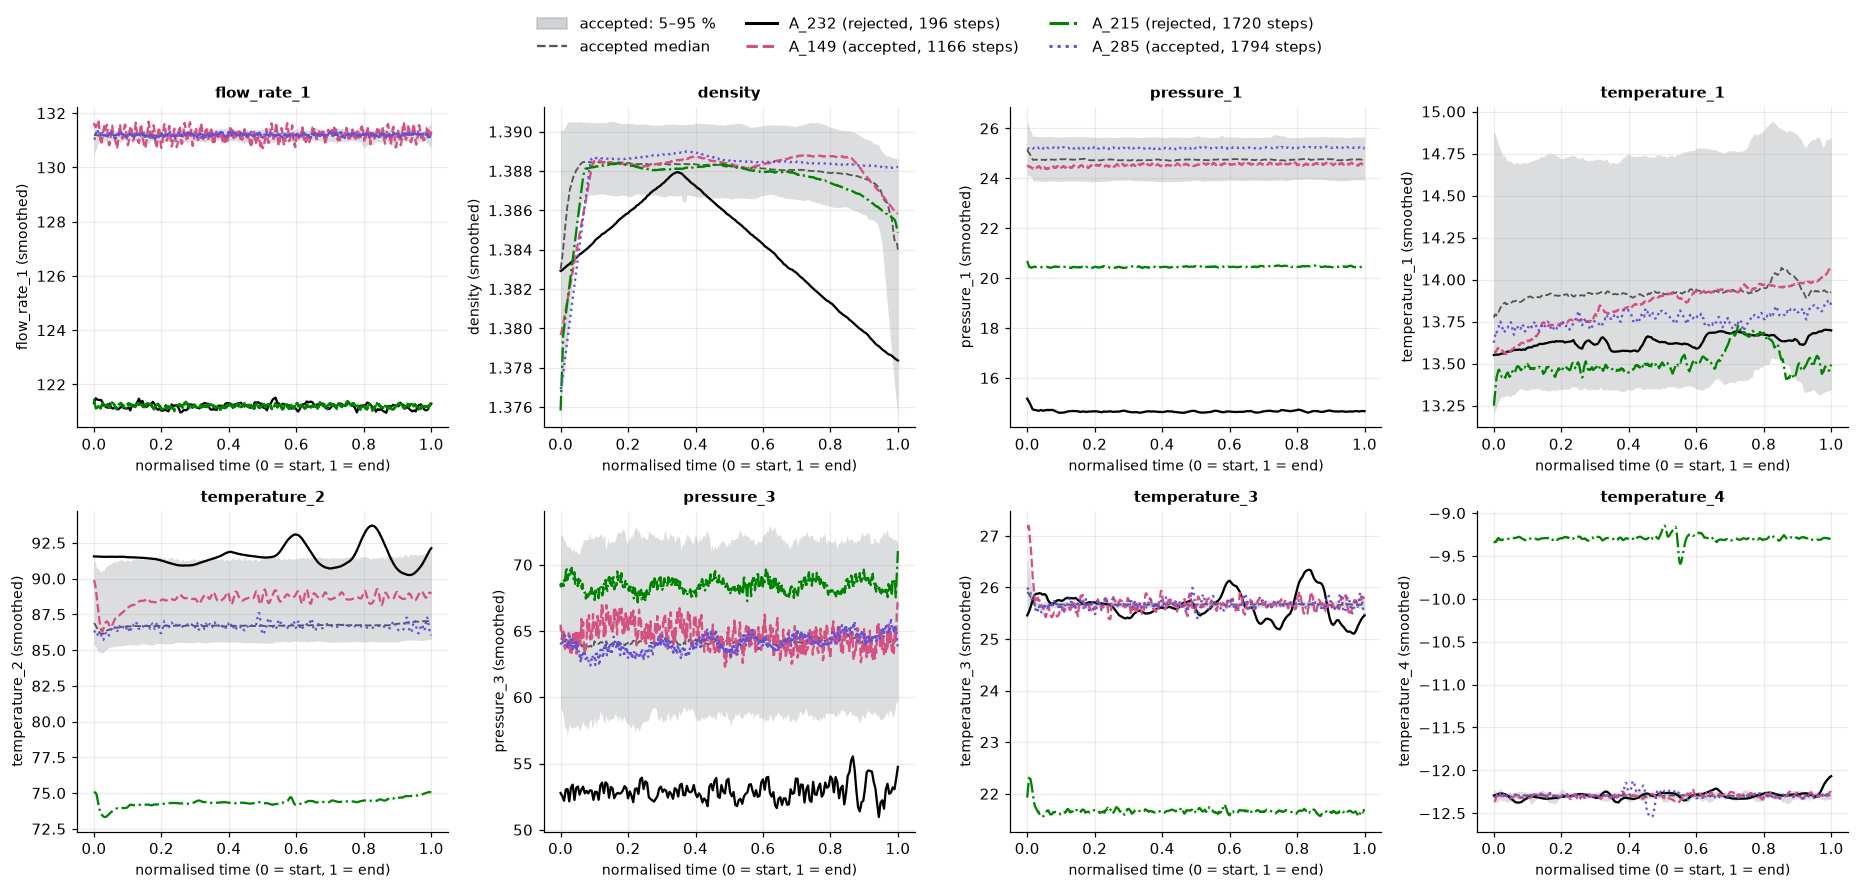

In [13]:
short=list(n_cal.nsmallest(4).index); print({b:(int(n_cal[b]),y[b]) for b in short})
fig,axs=plt.subplots(2,4,figsize=(17,7.5))
for ax,v in zip(axs.ravel(),["flow_rate_1","density","pressure_1","temperature_1","temperature_2","pressure_3","temperature_3","temperature_4"]):
    X=sm(Xc[v]); ax.fill_between(g,np.percentile(X[acc],5,axis=0),np.percentile(X[acc],95,axis=0),color=ACC,alpha=.3,lw=0); ax.plot(g,np.median(X[acc],0),lw=1.2,**MED_KW)
    for i,b in enumerate(short):
        x=cal[cal.batch_id==b]; ax.plot(x.tn,uniform_filter1d(x[v].values,max(5,len(x)//100),mode="nearest"),color=HL_COL[i],ls=HL_LS[i],lw=1.5)
    ax.set(title=v,xlabel="normalised time (0 = start, 1 = end)",ylabel=f"{v} (smoothed)")
top_legend(fig,[patch(ACC,"accepted: 5–95 %"),line(label="accepted median",lw=1.5,**MED_KW)]+[line(HL_COL[i],f"{b} ({y[b]}, {n_cal[b]} steps)",ls=HL_LS[i]) for i,b in enumerate(short)],ncol=3)
plt.tight_layout(); plt.show()